<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Ni4W_cuEST_SOC_DFT_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ni₄W electronic structure

Periodic density functional theory (DFT) gives a set of Kohn–Sham energies at each crystal wave vector, so their dispersion reveals where bands cross the metallic Fermi level. Yang et al. use spin–orbit coupling (SOC) in Figure 1c and relate gaps opened near spinless nodal lines to strong spin Berry curvature [1]. Here Quantum ESPRESSO calculates the bulk spinor bands, while NVIDIA CUDA Electronic Structure Theory (cuEST) calculates discrete levels for an isolated five-atom Ni₄W fragment on the graphics processing unit (GPU) [2–5].

| Symbol or term | Meaning |
| --- | --- |
| PBE | Perdew–Burke–Ernzerhof generalized gradient approximation [3] |
| PAW | Projector augmented-wave method, used here with fully relativistic PSlibrary datasets [4] |
| SCF | Self-consistent field cycle, which converges the electron density |
| `a`, `c` | Conventional tetragonal lattice parameters in ångströms (Å) |
| $k$, $n$, $E_{nk}$ | Crystal wave vector, band index, and spinor Kohn–Sham energy |
| $E_{\mathrm F}$ | Fermi energy from the periodic SCF mesh |
| $\sigma$ | Gaussian standard deviation for the heatmap, in electronvolts (eV) |
| HOMO | Highest occupied molecular orbital, used as the cluster energy reference |

Select a Colab GPU runtime with Python 3.12 or newer for the cuEST cells, preferably an L4 or A100. The periodic section runs on the central processing unit (CPU) and also works in a CPU runtime.

## References

1. Yang, Y. et al. (2025) ‘Large spin-orbit torque with multi-directional spin components in Ni₄W’, *Advanced Materials*, 37(32), 2416763. Figure 1c and Supplementary Section 1. https://doi.org/10.1002/adma.202416763
2. Giannozzi, P. et al. (2009) ‘QUANTUM ESPRESSO: A modular and open-source software project for quantum simulations of materials’, *Journal of Physics: Condensed Matter*, 21(39), 395502. https://doi.org/10.1088/0953-8984/21/39/395502
3. Perdew, J.P., Burke, K. and Ernzerhof, M. (1996) ‘Generalized gradient approximation made simple’, *Physical Review Letters*, 77(18), pp. 3865–3868. https://doi.org/10.1103/PhysRevLett.77.3865
4. Dal Corso, A. (2014) ‘Pseudopotentials periodic table: From H to Pu’, *Computational Materials Science*, 95, pp. 337–350. https://doi.org/10.1016/j.commatsci.2014.07.043
5. NVIDIA (2026) *cuEST 0.3.0 documentation and SCF examples*. [Documentation](https://docs.nvidia.com/cuda/cuest/0.3.0/) · [SCF examples](https://github.com/NVIDIA/CUDALibrarySamples/tree/4ad81eea85bcd344e1d148028ba6d508687cda50/cuEST/cuest_scf_examples)
6. Ngo, T.D. and Nagao, T. (2026) *First-principles optical properties and thermophotonic device parameters for Ni₄W / (I4/m, #87, Tetragonal) / AtomWork-Adv Material ID 4295424196*. NIMS Materials Data Repository. Ni₄W POSCAR, CC BY 4.0. https://doi.org/10.48505/nims.8142
7. Weigend, F. and Ahlrichs, R. (2005) ‘Balanced basis sets of split valence, triple zeta valence and quadruple zeta valence quality for H to Rn’, *Physical Chemistry Chemical Physics*, 7, pp. 3297–3305. https://doi.org/10.1039/B508541A

In [1]:
"""This script calculates periodic Ni4W bands and cuEST cluster levels."""

# --- Control Knobs ---
PRESET = "colab"  # "colab" or "paper_parameters"
POINTS_PER_SEGMENT = 12  # Sampling on the shortest band-path segment.
ENERGY_WINDOW_EV = (-0.6, 0.6)
BROADENING_EV = 0.018  # Heatmap Gaussian standard deviation in eV.

import os
from pathlib import Path
import shutil
import subprocess
import sys
import tempfile
from urllib.request import urlopen
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np

presets = {
    "colab": (5.730, 3.550, (4, 4, 4), 80, 500),
    "paper_parameters": (5.739, 3.566, (8, 8, 14), 90, 720),
}
A_ANGSTROM, C_ANGSTROM, SCF_MESH, ECUT_RY, RHO_CUT_RY = presets[PRESET]
if (POINTS_PER_SEGMENT < 2 or BROADENING_EV <= 0
        or ENERGY_WINDOW_EV[0] >= ENERGY_WINDOW_EV[1]):
    raise ValueError("Use a positive width, increasing energy limits, and two or more points.")

# Native solvers write inputs and intermediate files to this session directory.
session_dir = Path("/content")
work = Path(tempfile.mkdtemp(
    prefix="ni4w_dft_", dir=session_dir if session_dir.is_dir() else None,
))
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.weight": "normal",
    "axes.titleweight": "normal", "axes.labelweight": "normal",
})
print(f"{PRESET}: mesh {SCF_MESH}, cutoffs {ECUT_RY}/{RHO_CUT_RY} Ry")

colab: mesh (4, 4, 4), cutoffs 80/500 Ry


The bulk structure is body-centered tetragonal, with space group *I*4/*m* (No. 87). The five-atom primitive cell uses the NIMS Ni₄W fractional sites, placed at the lattice dimensions reported in the article for the Colab preset and in the supplement for the paper-parameter preset [1, 6]. Reciprocal coordinates from the conventional tetragonal inset of Figure 1c are transformed into the primitive basis before they reach the solver, which keeps the physical wave vectors fixed.


In [2]:
# --- Experimental-paper lattice and database fractional sites ---
a, c = A_ANGSTROM, C_ANGSTROM
conventional_cell = np.diag([a, a, c])
# NIMS POSCAR fractional positions transformed to the I4/m 8h orbit.
nickel_conv = np.array([
    [0.4, 0.2, 0.0], [-0.4, -0.2, 0.0],
    [-0.2, 0.4, 0.0], [0.2, -0.4, 0.0],
])
fractional_conventional = np.vstack((nickel_conv, [0.0, 0.0, 0.0]))
symbols = ("Ni", "Ni", "Ni", "Ni", "W")
primitive_transform = 0.5 * np.array([
    [-1, 1, 1], [1, -1, 1], [1, 1, -1],
])
primitive_cell = primitive_transform @ conventional_cell
fractional_primitive = np.mod(
    fractional_conventional @ np.linalg.inv(primitive_transform), 1.0
)
cluster_angstrom = fractional_conventional @ conventional_cell
HARTREE_EV = 27.211386245988
BOHR_ANGSTROM = 0.529177210903

# --- Fig. 1c labels in the conventional reciprocal coordinates ---
path_labels = (r"$\Gamma$", "X", "M", r"$\Gamma$", "Z", "R", "A", "Z")
special_points = np.array([
    [0, 0, 0], [0.5, 0, 0], [0.5, 0.5, 0], [0, 0, 0],
    [0, 0, 0.5], [0.5, 0, 0.5], [0.5, 0.5, 0.5], [0, 0, 0.5],
])
reciprocal_conventional = 2 * np.pi * np.linalg.inv(conventional_cell).T
segment_lengths = np.linalg.norm(
    np.diff(special_points, axis=0) @ reciprocal_conventional, axis=1
)
segment_counts = np.maximum(
    1, np.ceil(POINTS_PER_SEGMENT * segment_lengths / segment_lengths.min()).astype(int)
)
k_path_conventional = np.concatenate([
    *(np.linspace(left, right, n, endpoint=False)
      for left, right, n in zip(special_points[:-1], special_points[1:], segment_counts)),
    special_points[-1:],
])
k_path_cart = k_path_conventional @ reciprocal_conventional
k_path_primitive = k_path_conventional @ primitive_transform.T
distance = np.r_[0, np.cumsum(np.linalg.norm(np.diff(k_path_cart, axis=0), axis=1))]
tick_indices = np.r_[0, segment_counts.cumsum()]
tick_positions = distance[tick_indices]
print(f"Primitive cell: 4 Ni + 1 W, volume {np.linalg.det(primitive_cell):.3f} Å³")
print(f"Band path: {len(k_path_primitive)} points")

Primitive cell: 4 Ni + 1 W, volume 58.278 Å³
Band path: 103 points


## Periodic bands with spin–orbit coupling

Quantum ESPRESSO first converges the charge density on a three-dimensional mesh, then evaluates the bands along the Figure 1c path at fixed density. The authors report PBE, 90/720 Ry cutoffs, an 8 × 8 × 14 mesh and relaxed lattice constants of 5.739 and 3.566 Å in Supplementary Section 1 [1–4]. The `paper_parameters` preset applies these numeric settings to the notebook’s primitive cell, with public PAW potentials and database internal coordinates. The original pseudopotential files and relaxed internal coordinates are not specified in the supplement.

The Colab preset uses a coarser mesh to demonstrate the workflow. For quantitative comparison near avoided crossings, converge the Fermi energy and local band separations with respect to mesh, cutoffs, and electronic smearing. The authors’ spin Berry curvature and spin Hall response also require velocity and spin-current matrix elements from a Wannier model [1].

Run the solver setup cell before the periodic calculation. It installs Quantum ESPRESSO 7.6 and its matching Open MPI runtime in an isolated environment. The periodic cell calls both executables from that environment. [Conda-forge package](https://github.com/conda-forge/qe-feedstock)


In [3]:
# --- Install Quantum ESPRESSO 7.6 and its matching MPI runtime ---
import platform
import tarfile

qe_platform = {"x86_64": "linux-64", "aarch64": "linux-aarch64"}.get(platform.machine())
if not sys.platform.startswith("linux") or qe_platform is None:
    raise RuntimeError("Use a Linux Colab runtime for this solver setup.")

qe_root = session_dir / ".ni4w_qe" if session_dir.is_dir() else work / "qe_tools"
qe_root.mkdir(parents=True, exist_ok=True)
qe_prefix = qe_root / "qe-7.6"
qe_bin = qe_prefix / "bin"
pw = qe_bin / "pw.x"
mpi = qe_bin / "mpirun"

if not (pw.is_file() and mpi.is_file()):
    micromamba = qe_root / "micromamba"
    if not micromamba.is_file():
        archive = qe_root / "micromamba.tar.bz2"
        with urlopen(
            f"https://micro.mamba.pm/api/micromamba/{qe_platform}/2.3.3",
            timeout=120,
        ) as response, archive.open("wb") as target:
            shutil.copyfileobj(response, target)
        with tarfile.open(archive, "r:bz2") as bundle:
            member = bundle.getmember("bin/micromamba")
            with bundle.extractfile(member) as binary:
                micromamba.write_bytes(binary.read())
        micromamba.chmod(0o755)
        archive.unlink()

    subprocess.run(
        [
            str(micromamba), "--no-rc", "create", "--yes",
            "--override-channels", "-c", "conda-forge", "-p", str(qe_prefix),
            "qe=7.6=mpi_openmpi*", "libblas=*=*openblas",
        ],
        env=os.environ | {"MAMBA_ROOT_PREFIX": str(qe_root / "mamba-cache")},
        check=True,
    )

if not (pw.is_file() and mpi.is_file()):
    raise RuntimeError("The Quantum ESPRESSO installation is missing pw.x or mpirun.")
print(f"Quantum ESPRESSO 7.6: {pw}")

Quantum ESPRESSO 7.6: /content/.ni4w_qe/qe-7.6/bin/pw.x


In [4]:
# --- Calculate the periodic spinor bands ---
qe_dir = work / "periodic"
qe_dir.mkdir(exist_ok=True)
pseudo_files = {
    element: f"{element}.rel-pbe-spn-kjpaw_psl.1.0.0.UPF"
    for element in ("Ni", "W")
}
for filename in pseudo_files.values():
    destination = qe_dir / filename
    if not destination.exists():
        with urlopen(
            "https://pseudopotentials.quantum-espresso.org/upf_files/" + filename,
            timeout=120,
        ) as response:
            raw = response.read()
        if b"<UPF" not in raw or b'has_so="true"' not in raw:
            raise ValueError(f"Expected a fully relativistic UPF for {filename}.")
        destination.write_bytes(raw)

# Both stages use the converged SCF potential. The k path has zero role in SCF.
mesh = " ".join(map(str, SCF_MESH))
if "qe_bin" not in globals():
    raise RuntimeError("Run the Quantum ESPRESSO 7.6 setup cell first.")
pw = qe_bin / "pw.x"
mpi = qe_bin / "mpirun"
if not (pw.is_file() and mpi.is_file()):
    raise RuntimeError("Rerun the Quantum ESPRESSO 7.6 setup cell.")
np_cpu = min(2, len(os.sched_getaffinity(0)))
pw_command = [str(pw)]
if np_cpu > 1:
    pw_command = [
        str(mpi), "--oversubscribe", "-np", str(np_cpu),
        "--mca", "pml", "ob1", "--mca", "btl", "self,sm",
        str(pw), "-nk", str(np_cpu),
    ]
qe_env = os.environ | {
    "PATH": os.pathsep.join((str(qe_bin), os.environ.get("PATH", os.defpath))),
    "LD_LIBRARY_PATH": str(qe_bin.parent / "lib"),
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OMPI_ALLOW_RUN_AS_ROOT": "1",
    "OMPI_ALLOW_RUN_AS_ROOT_CONFIRM": "1",
}
position_rows = "\n".join(
    species + " " + " ".join(f"{value:.12f}" for value in position)
    for species, position in zip(symbols, fractional_primitive)
)
cell_rows = "\n".join(
    " ".join(f"{value:.12f}" for value in vector) for vector in primitive_cell
)
band_k_rows = "\n".join(
    " ".join(f"{value:.12f}" for value in point) + " 1.0"
    for point in k_path_primitive
)
scf_bands_xml = qe_dir / "ni4w.save" / "data-file-schema.xml"
for stage, k_card in (
    ("scf", f"K_POINTS automatic\n{mesh} 0 0 0"),
    ("bands", f"K_POINTS crystal\n{len(k_path_primitive)}\n{band_k_rows}"),
):
    start_potential = "atomic" if stage == "scf" else "file"
    disk_io = "medium"
    input_text = f"""
&CONTROL
  calculation = '{stage}', prefix = 'ni4w', outdir = '.',
  pseudo_dir = '.', disk_io = '{disk_io}',
/
&SYSTEM
  ibrav = 0, nat = 5, ntyp = 2, input_dft = 'PBE',
  ecutwfc = {ECUT_RY}, ecutrho = {RHO_CUT_RY}, nbnd = 104,
  noncolin = .true., lspinorb = .true.,
  occupations = 'smearing', smearing = 'mv', degauss = 0.02,
/
&ELECTRONS
  conv_thr = 1.0d-8, electron_maxstep = 150,
  mixing_mode = 'local-TF', mixing_beta = 0.18,
  startingpot = '{start_potential}', startingwfc = 'atomic+random',
  diago_full_acc = {'.false.' if stage == 'scf' else '.true.'},
/
ATOMIC_SPECIES
Ni 58.6934 {pseudo_files['Ni']}
W 183.84 {pseudo_files['W']}
CELL_PARAMETERS angstrom
{cell_rows}
ATOMIC_POSITIONS crystal
{position_rows}
{k_card}
""".strip() + "\n"
    input_file = qe_dir / f"{stage}.in"
    log_file = qe_dir / f"{stage}.out"
    input_file.write_text(input_text)
    print(f"Running {stage} with Quantum ESPRESSO 7.6 on {np_cpu} CPU rank(s).", flush=True)
    with log_file.open("w") as log:
        completed = subprocess.run(
            [*pw_command, "-in", input_file.name], cwd=qe_dir,
            stdout=log, stderr=subprocess.STDOUT, env=qe_env, check=False,
        )
    log_text = log_file.read_text(errors="replace")
    scf_converged = "convergence has been achieved" in log_text.lower()
    if completed.returncode or "JOB DONE." not in log_text or (
        stage == "scf" and not scf_converged
    ):
        print("\n".join(log_text.splitlines()[-65:]))
        raise RuntimeError(f"Quantum ESPRESSO {stage} failed. See {log_file}.")
    output = ET.parse(scf_bands_xml).getroot().find("output")
    bs = output.find("band_structure")
    if stage == "scf":
        fermi_ev = float(bs.findtext("fermi_energy")) * HARTREE_EV
        print(f"SCF Fermi energy: {fermi_ev:.6f} eV")
    else:
        rows = bs.findall("ks_energies")
        energies_ev = HARTREE_EV * np.stack([
            np.fromstring(row.findtext("eigenvalues"), sep=" ") for row in rows
        ])
        actual_k = np.stack([
            np.fromstring(row.findtext("k_point"), sep=" ") for row in rows
        ])
        alat_bohr = float(output.find("atomic_structure").get("alat"))
        actual_k = actual_k * (2 * np.pi / (alat_bohr * BOHR_ANGSTROM))
        np.testing.assert_allclose(actual_k, k_path_cart, atol=2e-6, rtol=2e-6)
        if not np.isfinite(energies_ev).all() or not np.isfinite(fermi_ev):
            raise ValueError("The band calculation returned nonfinite energies.")
        bands_relative_ev = energies_ev - fermi_ev
        print(f"Calculated {bands_relative_ev.shape[1]} spinor eigenvalues at "
              f"each of {len(rows)} k points.")

Running scf with Quantum ESPRESSO 7.6 on 2 CPU rank(s).
SCF Fermi energy: 19.536562 eV
Running bands with Quantum ESPRESSO 7.6 on 2 CPU rank(s).
Calculated 104 spinor eigenvalues at each of 103 k points.


## Band intensity heatmap

Each calculated eigenvalue contributes a normalized Gaussian centered at its energy relative to the SCF Fermi level. The sum at each wave vector gives the plotted intensity in states per electronvolt, without spin or orbital matrix-element weights. Figure 1c colors its bands by signed spin Berry curvature, whereas the heatmap below represents the energy and momentum distribution of the calculated eigenvalues [1].

$$
I_{\sigma}(k,E)=\sum_n\frac{\exp[-(E-(E_{nk}-E_{\mathrm F}))^2/(2\sigma^2)]}{\sqrt{2\pi}\,\sigma}.
$$


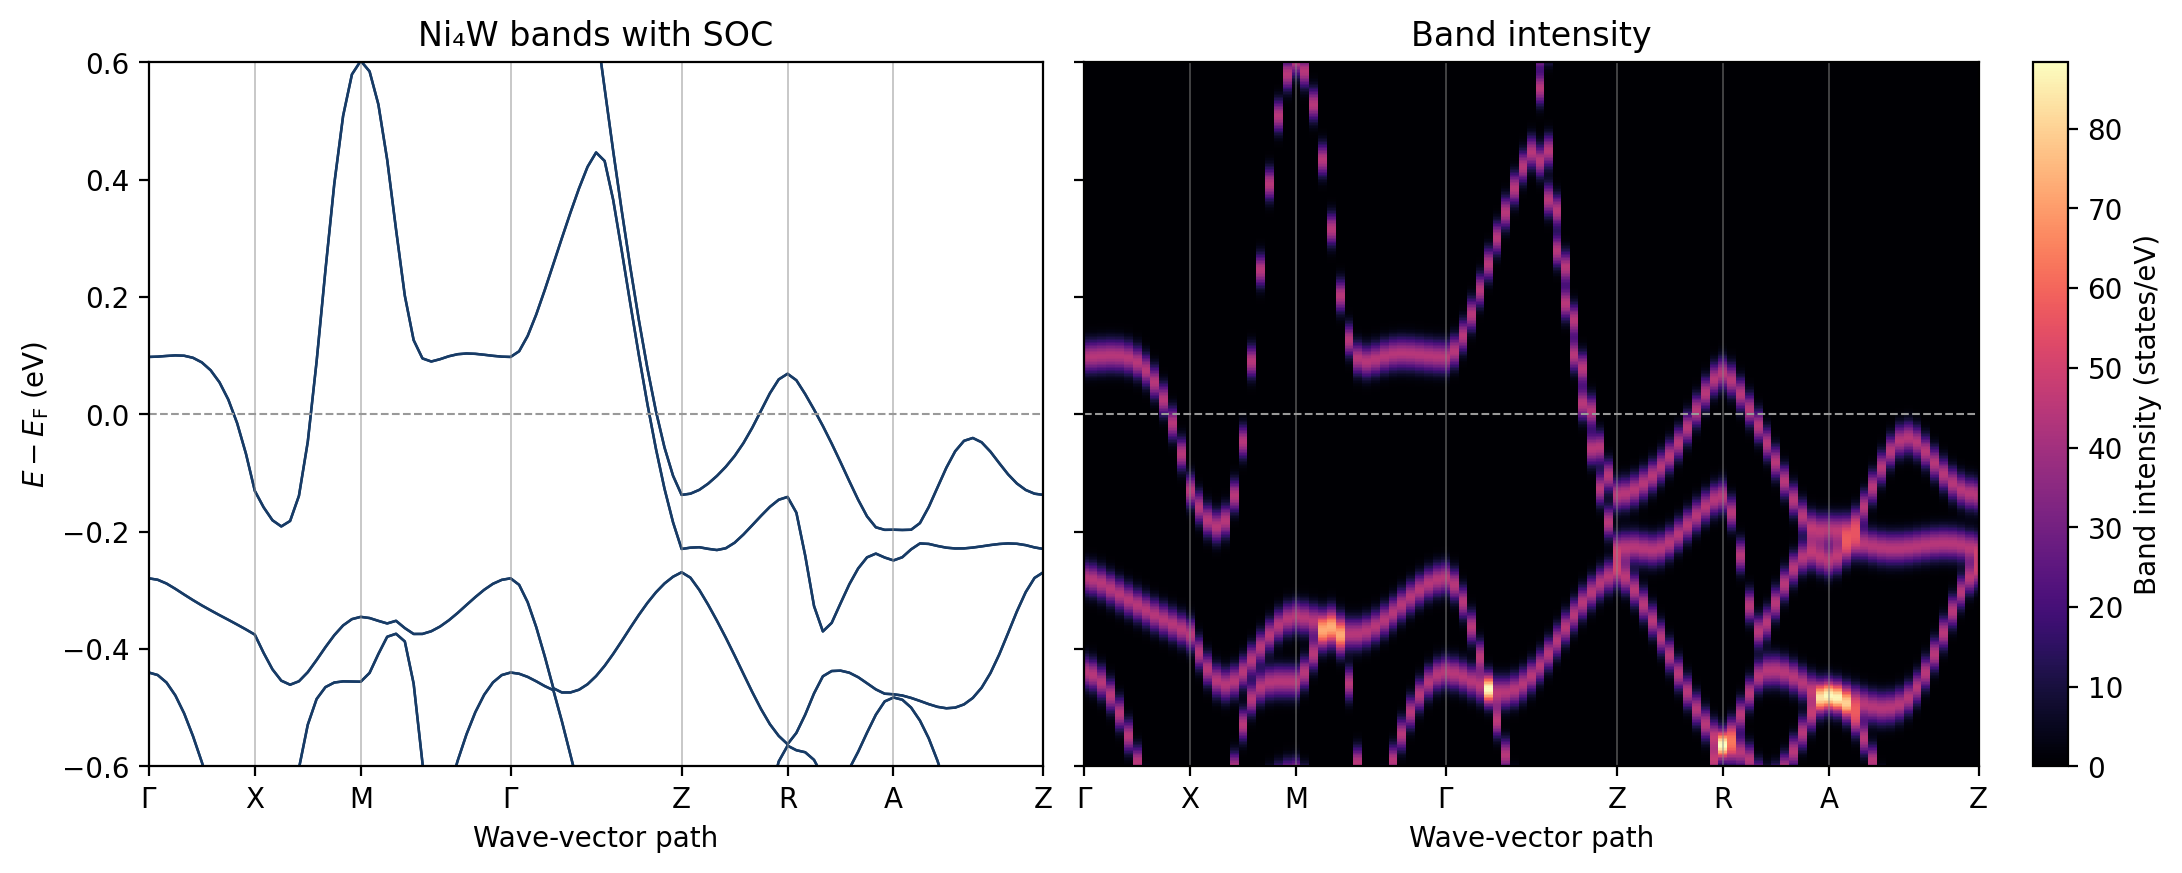

In [5]:
# --- Render lines and energy–momentum intensity from the same eigenvalues ---
energy_grid = np.linspace(*ENERGY_WINDOW_EV, 481)
delta = (
    energy_grid[:, None, None] - bands_relative_ev[None, :, :]
) / BROADENING_EV
intensity = np.sum(np.exp(-0.5 * delta**2), axis=2) / (
    np.sqrt(2 * np.pi) * BROADENING_EV
)
if np.min(bands_relative_ev[:, -1]) < ENERGY_WINDOW_EV[1] + 4 * BROADENING_EV:
    print("Increase nbnd in &SYSTEM to cover the upper plot window.")
fig, (line_ax, map_ax) = plt.subplots(
    1, 2, figsize=(10.8, 4.25), dpi=200, sharey=True, layout="constrained",
)
line_ax.plot(distance, bands_relative_ev, color="#173b66", linewidth=0.9)
spectral_map = map_ax.pcolormesh(
    distance, energy_grid, intensity, cmap="magma",
    shading="auto", rasterized=True,
)
fig.colorbar(spectral_map, ax=map_ax, label="Band intensity (states/eV)")
line_ax.set_ylabel(r"$E - E_{\mathrm{F}}$ (eV)")
for ax, title in zip((line_ax, map_ax), ("Ni₄W bands with SOC", "Band intensity")):
    for tick in tick_positions[1:-1]:
        ax.axvline(tick, color="0.55", linewidth=0.55, alpha=0.6)
    ax.axhline(0, color="0.6", linestyle="--", linewidth=0.75)
    ax.set(xticks=tick_positions, xticklabels=path_labels,
           xlim=(distance[0], distance[-1]), ylim=ENERGY_WINDOW_EV,
           title=title, xlabel="Wave-vector path")
plt.show()

## cuEST calculation for an isolated Ni₄W fragment

NVIDIA cuEST evaluates the one-electron, direct Coulomb, and Perdew–Burke–Ernzerhof (PBE) exchange-correlation terms on the GPU [3, 5]. SciPy minimizes the restricted Kohn–Sham energy by rotating the occupied subspace while preserving orbital orthogonality. The calculation reports the unshifted eigenvalues after checking the coupling between occupied and virtual orbitals.

The fragment consists of one W atom and four Ni sites from the bulk structure, with a def2-SVP basis and a scalar effective core potential for tungsten [7]. Its fixed geometry yields discrete orbitals referenced to the highest occupied molecular orbital. Periodicity and spin–orbit coupling enter the bulk calculation above.


In [6]:
# --- Install cuEST in its own CUDA 12 environment ---
if sys.version_info < (3, 12):
    raise RuntimeError("Use a Colab runtime with Python 3.12 or newer.")
nvidia_smi = shutil.which("nvidia-smi")
if not nvidia_smi:
    raise RuntimeError("Select a Colab GPU runtime for the cuEST section.")
gpu_info = subprocess.check_output(
    [nvidia_smi, "--query-gpu=name,compute_cap,driver_version", "--format=csv,noheader"],
    text=True,
).strip()
print(gpu_info)
gpu_cap = float(gpu_info.splitlines()[0].split(",")[1].strip())
if gpu_cap < 8.0:
    raise RuntimeError("Choose a supported Ampere or newer GPU, such as L4 or A100.")

commit = "4ad81eea85bcd344e1d148028ba6d508687cda50"
uv = shutil.which("uv")
if uv is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
    uv = shutil.which("uv")
if uv is None:
    raise RuntimeError("Install uv in the current Colab runtime.")
venv = work / "cuest-env"
cluster_python = venv / "bin" / "python"
if not cluster_python.exists():
    subprocess.run([uv, "venv", "--python", sys.executable, str(venv)], check=True)
subprocess.run(
    [
        uv, "pip", "install", "--python", str(cluster_python),
        "cuest-examples[cu12] @ "
        f"git+https://github.com/NVIDIA/CUDALibrarySamples.git@{commit}#subdirectory=cuEST",
        "nvidia-cuest-cu12==0.3.0", "nvmath-python==1.0.1", "scipy>=1.15,<2",
        "cuda-bindings==12.9.*", "nvidia-cuda-runtime-cu12==12.9.*",
        "nvidia-cuda-nvrtc-cu12==12.9.*", "nvidia-nvjitlink-cu12==12.9.*",
    ],
    check=True,
)
site_packages = Path(subprocess.check_output(
    [str(cluster_python), "-I", "-c", "import sysconfig; print(sysconfig.get_path('purelib'))"],
    text=True,
).strip())
library_dirs = sorted((site_packages / "nvidia").glob("*/lib"))
if not library_dirs:
    raise RuntimeError(f"No CUDA wheel library directories found under {site_packages}.")
existing_paths = os.environ.get("LD_LIBRARY_PATH", "").split(os.pathsep)
cluster_env = os.environ | {
    "LD_LIBRARY_PATH": os.pathsep.join(dict.fromkeys(
        [*(str(path) for path in library_dirs), *(path for path in existing_paths if path)]
    )),
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
}
cluster_command = [str(cluster_python), "-I", "-X", "faulthandler", "-u"]
preflight = """
from cuda.bindings import runtime
from importlib.metadata import version

status, count = runtime.cudaGetDeviceCount()
if status != runtime.cudaError_t.cudaSuccess or count == 0:
    raise RuntimeError(f"CUDA device discovery failed ({status.name}, {count} devices).")
status, runtime_version = runtime.cudaRuntimeGetVersion()
if status != runtime.cudaError_t.cudaSuccess or not 12000 <= runtime_version < 13000:
    raise RuntimeError(f"Expected a CUDA 12 runtime, got {runtime_version} ({status.name}).")

import cuest_scf as scf
import numpy as np

handle = scf.CuestHandle()
matrix = scf.GPUMatrix.from_numpy(np.diag([1.0, 2.0]))
evaluated, _ = scf.GPUMatrixUtility.eigh(matrix=matrix)
np.testing.assert_allclose(evaluated.to_numpy().ravel(), [1.0, 2.0])
print(f"cuEST {version('nvidia-cuest-cu12')} | CUDA runtime {runtime_version} | GPU check passed.")
"""
probe = subprocess.run(
    [*cluster_command, "-c", preflight], env=cluster_env,
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, encoding="utf-8", errors="replace", check=False,
)
if probe.stdout:
    print(probe.stdout.rstrip(), flush=True)
if probe.returncode:
    raise RuntimeError(f"cuEST GPU setup failed with exit code {probe.returncode}.")

NVIDIA L4, 8.9, 580.82.07
cuEST 0.3.0 | CUDA runtime 12090 | GPU check passed.


In [ ]:
# --- Compute discrete levels of an isolated five-atom Ni4W fragment ---
cluster_ev = cluster_relative_ev = nocc = cluster_total = cluster_residual = None
cluster_dir = work / "cluster"
cluster_dir.mkdir(exist_ok=True)
cluster_result = cluster_dir / "cluster_levels.npz"
cluster_result.unlink(missing_ok=True)
basis_url = (
    "https://raw.githubusercontent.com/NVIDIA/CUDALibrarySamples/"
    f"{commit}/cuEST/cuest_scf_examples/data/gbs/"
)
for filename in ("def2-svp.gbs", "minao-1.gbs", "def2-svp-ecp.gbs"):
    destination = cluster_dir / filename
    if not destination.is_file() or destination.stat().st_size == 0:
        with urlopen(basis_url + filename, timeout=60) as response:
            raw = response.read()
        if b"****" not in raw and b"W-ECP" not in raw.upper():
            raise ValueError(f"Unexpected basis data in {filename}.")
        destination.write_bytes(raw)

geometry_rows = [
    symbol + " " + " ".join(f"{value:.10f}" for value in xyz)
    for symbol, xyz in zip(symbols, cluster_angstrom, strict=True)
]
(cluster_dir / "ni4w.xyz").write_text(
    "\n".join([str(len(symbols)), "Isolated Ni4W fragment", *geometry_rows]) + "\n",
    encoding="utf-8",
)
cluster_script = r'''
"""This script converges a restricted Ni4W PBE solution with cuEST integrals."""

from itertools import count

import numpy as np
from scipy.linalg import eigh, qr, solve_triangular
from scipy.optimize import minimize

import cuest_scf as scf

# --- Cluster basis and one-electron integrals ---
molecule = scf.Molecule.parse_from_xyz_file("ni4w.xyz")
primary = scf.AOBasis.parse_from_gbs_file("def2-svp.gbs", molecule=molecule)
minao = scf.AOBasis.parse_from_gbs_file("minao-1.gbs", molecule=molecule)
ecp = scf.ECPBasis.parse_from_gbs_file("def2-svp-ecp.gbs", molecule=molecule)
handle = scf.CuestHandle()
calculation = scf.RHF(
    cuest_handle=handle, molecule=molecule, charge=0,
    primary=primary, auxiliary=primary, minao=minao, ecp_basis=ecp,
    xc_functional_name="PBE", xc_grid_family="SG", xc_grid_level=1,
    fock_method="directjk", print_level=0, print_timings=False,
)

electron_count = int(molecule.N.sum()) - ecp.nelectron
nocc = electron_count // 2
overlap = calculation.compute_overlap().to_numpy()
overlap_values, overlap_vectors = eigh(overlap)
keep = overlap_values > 1e-6
ortho = overlap_vectors[:, keep] / np.sqrt(overlap_values[keep])
if electron_count != 126 or ortho.shape[1] <= nocc:
    raise RuntimeError("Unexpected electron count or insufficient orbital basis rank.")
core = (
    calculation.compute_kinetic().to_numpy()
    + calculation.compute_potential().to_numpy()
    + calculation.compute_ecp_potential().to_numpy()
)
nuclear_energy = calculation.compute_Enuc()


def build_fock(occupied):
    """Use cuEST to evaluate PBE energy and Fock matrix for occupied AO rows."""
    occupied = np.ascontiguousarray(occupied)
    density = occupied.T @ occupied  # Density for one spin.
    coulomb = calculation.compute_coulomb(
        D=scf.GPUMatrix.from_numpy(density),
    ).to_numpy()
    xc_energy, xc_potential = calculation.compute_local_exchange_correlation(
        Cocc=scf.GPUMatrix.from_numpy(occupied),
    )
    fock = core + 2.0 * coulomb + xc_potential.to_numpy()
    energy = nuclear_energy + 2.0 * np.sum(density * (core + coulomb)) + xc_energy
    return (fock + fock.T) * 0.5, energy


# --- Variational orbital optimization ---
# The superposition of atomic densities is used only to seed the first Fock matrix.
calculation.compute_guess()
initial_fock, energy_zero = build_fock(calculation.tensors["Cocc"].to_numpy())
orbital_energies, rotation = eigh(ortho.T @ initial_fock @ ortho)
chart = ortho @ rotation
occupied_identity = np.eye(nocc)
fock_builds = count(1)
print(f"Optimizing {nocc} occupied orbitals in {chart.shape[1]} basis functions.")


def objective(parameters):
    """Evaluate the energy and its gradient in occupied-virtual coordinates."""
    trial = np.vstack((occupied_identity, parameters.reshape(scale.shape) * scale))
    metric_factor = np.linalg.cholesky(trial.T @ trial)
    orthogonal = solve_triangular(metric_factor, trial.T, lower=True).T
    fock, energy = build_fock((chart @ orthogonal).T)
    applied = (chart.T @ fock @ chart) @ orthogonal
    residual = applied - orthogonal @ (orthogonal.T @ applied)
    gradient = 4.0 * solve_triangular(metric_factor.T, residual.T).T[nocc:] * scale
    build = next(fock_builds)
    if build % 25 == 0:
        print(f"Fock build {build:3d} | E = {energy:.10f} Ha")
    return energy - energy_zero, gradient.ravel()


for step_limit in (180, 100, 100):
    print(f"Minimizing PBE energy for up to {step_limit} iterations.")
    # Approximate the inverse curvature with current orbital-energy differences.
    gaps = orbital_energies[nocc:, None] - orbital_energies[None, :nocc]
    scale = 1.0 / np.sqrt(np.maximum(gaps, 0.02))
    result = minimize(
        objective, np.zeros(scale.size), method="L-BFGS-B", jac=True,
        options={"maxiter": step_limit, "maxcor": 12, "gtol": 1e-7, "ftol": 1e-15},
    )
    trial = np.vstack((occupied_identity, result.x.reshape(scale.shape) * scale))
    rotation, _ = qr(trial, mode="full")
    chart = chart @ rotation
    fock, total_hartree = build_fock(chart[:, :nocc].T)
    projected = chart.T @ fock @ chart
    residual = np.max(np.abs(projected[nocc:, :nocc]))
    filled, filled_rotation = eigh(projected[:nocc, :nocc])
    empty, empty_rotation = eigh(projected[nocc:, nocc:])
    gap = empty[0] - filled[-1]
    print(
        f"{result.nfev} Fock builds | E = {total_hartree:.10f} Ha | "
        f"occupied–virtual residual = {residual:.2e} Ha | gap = {gap:.3e} Ha"
    )
    if residual <= 1e-6 and gap >= 0.0:
        levels = np.linalg.eigvalsh(projected)
        break

    # Recenter the orbital rotations without changing the density.
    chart = np.column_stack((
        chart[:, :nocc] @ filled_rotation, chart[:, nocc:] @ empty_rotation,
    ))
    orbital_energies = np.r_[filled, empty]
    energy_zero = total_hartree
else:
    raise RuntimeError(
        f"The Ni4W PBE solution failed the unshifted orbital checks "
        f"(residual {residual:.2e} Ha, gap {gap:.3e} Ha)."
    )

if not np.isfinite(levels).all() or not np.isfinite(total_hartree):
    raise RuntimeError("The cuEST cluster spectrum contains non-finite values.")
np.savez(
    "cluster_levels.npz", eigenvalues_hartree=levels,
    nocc=nocc, total_hartree=total_hartree, residual_hartree=residual,
)
print(f"Saved {levels.size} unshifted molecular levels.")
'''
(cluster_dir / "solve_cluster.py").write_text(cluster_script, encoding="utf-8")
cluster_log = cluster_dir / "cuest_cluster.log"
with cluster_log.open("w", encoding="utf-8", buffering=1) as log, subprocess.Popen(
    [*cluster_command, "solve_cluster.py"], cwd=cluster_dir, env=cluster_env,
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, encoding="utf-8", errors="replace",
) as child:
    try:
        for line in child.stdout:
            log.write(line)
            print(line, end="", flush=True)
    except KeyboardInterrupt:
        child.terminate()
        raise
    return_code = child.wait()

if return_code:
    cluster_result.unlink(missing_ok=True)
    log_tail = "\n".join(cluster_log.read_text(encoding="utf-8").splitlines()[-20:])
    raise RuntimeError(
        f"cuEST cluster subprocess exited with status {return_code}. "
        f"Full output is in {cluster_log}.\n{log_tail}"
    )
if not cluster_result.is_file():
    raise RuntimeError(f"cuEST did not produce cluster levels. See {cluster_log}.")

with np.load(cluster_result, allow_pickle=False) as data:
    spectrum = data["eigenvalues_hartree"] * HARTREE_EV
    occupied_count = int(data["nocc"].item())
    total_energy = float(data["total_hartree"].item())
    orbital_residual = float(data["residual_hartree"].item())

if (
    spectrum.ndim != 1 or not 0 < occupied_count < spectrum.size
    or not np.isfinite(spectrum).all() or not np.isfinite(total_energy)
    or not 0.0 <= orbital_residual <= 1e-6
):
    raise RuntimeError(f"Invalid cuEST cluster result in {cluster_result}.")

cluster_ev = spectrum
nocc = occupied_count
cluster_total = total_energy
cluster_residual = orbital_residual
cluster_relative_ev = cluster_ev - cluster_ev[nocc - 1]
print(f"Cluster PBE total energy: {cluster_total:.8f} Ha")
print(f"Occupied–virtual Fock residual: {cluster_residual:.2e} Ha")
print(f"HOMO–LUMO Kohn–Sham separation: {cluster_relative_ev[nocc]:.3f} eV")

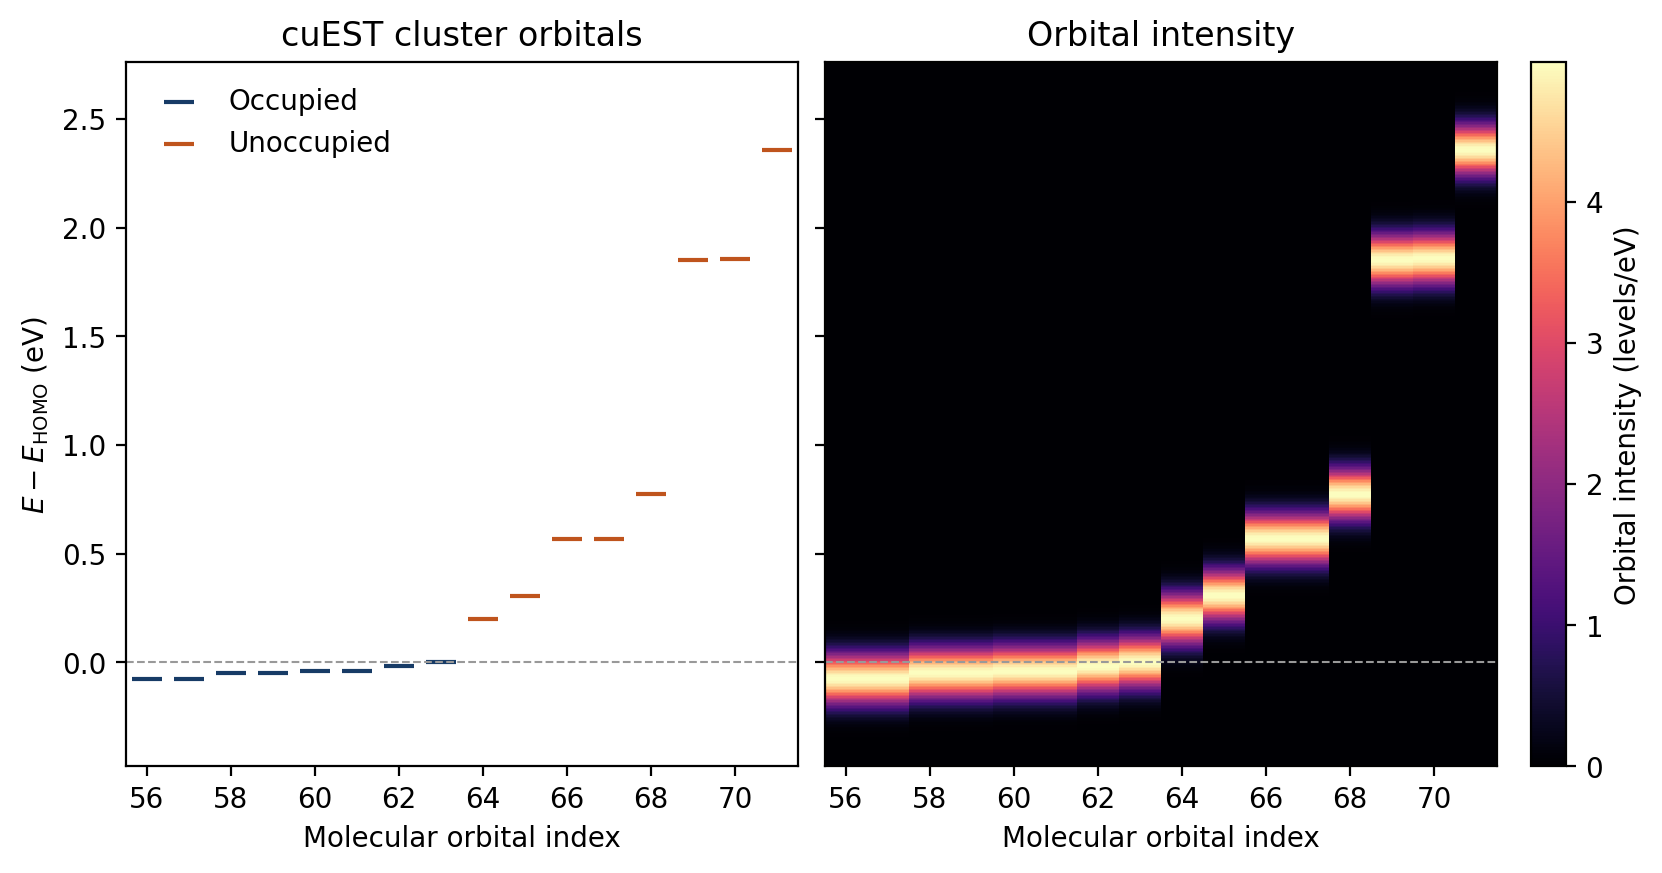

In [8]:
# --- Render molecular levels near the highest occupied orbital ---
if cluster_relative_ev is None:
    raise RuntimeError("Run the cuEST cluster calculation successfully before plotting.")
near_frontier = np.arange(max(0, nocc - 8), min(cluster_ev.size, nocc + 8))
level_energy = cluster_relative_ev[near_frontier]
occupied = near_frontier < nocc
cluster_grid = np.linspace(level_energy.min() - 0.4, level_energy.max() + 0.4, 480)
cluster_sigma = 0.08  # eV
spread = (cluster_grid[:, None] - level_energy[None, :]) / cluster_sigma
cluster_intensity = np.exp(-0.5 * spread**2) / (np.sqrt(2 * np.pi) * cluster_sigma)

from matplotlib.ticker import MaxNLocator

fig, (level_ax, heat_ax) = plt.subplots(
    1, 2, figsize=(8.2, 4.25), dpi=200, sharex=True, sharey=True, layout="constrained",
)
level_ax.scatter(near_frontier[occupied] + 1, level_energy[occupied],
                 marker="_", s=115, color="#173b66", label="Occupied")
level_ax.scatter(near_frontier[~occupied] + 1, level_energy[~occupied],
                 marker="_", s=115, color="#bf541d", label="Unoccupied")
level_ax.legend(frameon=False, loc="upper left")
level_map = heat_ax.pcolormesh(
    near_frontier + 1, cluster_grid, cluster_intensity, cmap="magma",
    shading="auto", rasterized=True,
)
fig.colorbar(level_map, ax=heat_ax, label="Orbital intensity (levels/eV)")
level_ax.set_ylabel(r"$E - E_{\mathrm{HOMO}}$ (eV)")
for ax, title in zip((level_ax, heat_ax), ("cuEST cluster orbitals", "Orbital intensity")):
    ax.axhline(0, color="0.6", linestyle="--", linewidth=0.75)
    ax.set(title=title, xlabel="Molecular orbital index")
heat_ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
plt.show()